In [15]:
print("Handwritten Character Recognition")
print("My First Machine Learning Project!")

Handwritten Character Recognition
My First Machine Learning Project!


Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


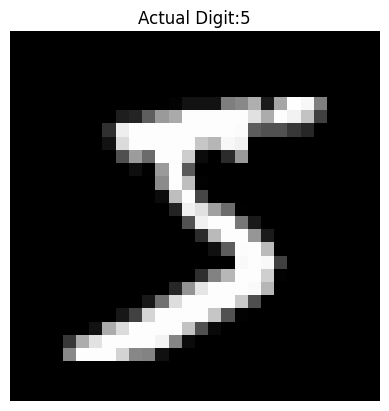

In [16]:
import tensorflow as tf
import matplotlib.pyplot as plt
#Load the MNIST handwritten digit dataset
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.mnist.load_data()
print("Training images:",x_train.shape)
print("Testing images:",x_test.shape)
#Display one handwritten digit
plt.imshow(x_train[0],cmap="gray")
plt.title(f"Actual Digit:{y_train[0]}")
plt.axis("off")
plt.show()

In [17]:
#Normalize the image pixel values
x_train=x_train/255.0
x_test=x_test/255.0
#Build the neural network model
model=tf.keras.Sequential([tf.keras.layers.Flatten(input_shape=(28,28)),tf.keras.layers.Dense(128,activation="relu"),tf.keras.layers.Dropout(0.2),tf.keras.layers.Dense(10,activation="softmax")])
#Compile the model
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
#Train the model
model.fit(x_train,y_train,epochs=3)
#Evaluate the model
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("Test Accuracy:",round(test_accuracy*100,2),"%")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9118 - loss: 0.3009
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9567 - loss: 0.1468
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9676 - loss: 0.1086
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9734 - loss: 0.0882
Test Accuracy: 97.34 %


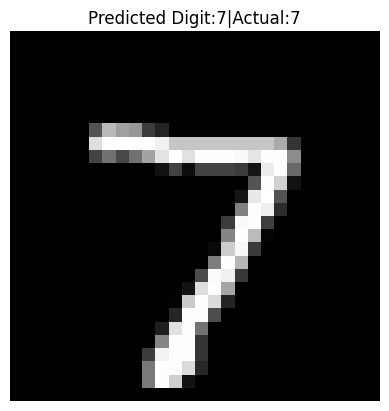

Predicted Digit: 7
Actual Digit: 7


In [18]:
import numpy as np
import matplotlib.pyplot as plt
#Select one test image
index=0
image=x_test[index]
#Predict the digit
prediction=model.predict(image.reshape(1,28,28),verbose=0)
predicted_digit=np.argmax(prediction)
#Display the result
plt.imshow(image,cmap="gray")
plt.title(f"Predicted Digit:{predicted_digit}|Actual:{y_test[index]}")
plt.axis("off")
plt.show()
print("Predicted Digit:",predicted_digit)
print("Actual Digit:",y_test[index])


In [19]:
model.save("handwritten_digit_model.keras")
print("Model saved successfully!")

Model saved successfully!
